In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astroquery.ipac.nexsci.nasa_exoplanet_archive import NasaExoplanetArchive

table = NasaExoplanetArchive.query_criteria(
    table="ps",
    select="pl_name, pl_dens, pl_rade, pl_masse",
    where="pl_dens IS NOT NULL AND default_flag=1"
)

df = table.to_pandas()

In [2]:
G = 6.67430e-11  # m^3 kg^-1 s^-2

def calculate_breakup_period(density_g_cm3):
    rho = density_g_cm3 * 1000.0 # Convert g/cm^3 to kg/m^3
    
    P_sec = np.sqrt((3 * np.pi) / (G * rho)) # Equation (9): P_breakup = sqrt(3 * pi / (G * rho))
    
    P_hours = P_sec / 3600.0 # Convert seconds to hours
    return P_hours

# Compute breakup rotation period limit for each planet in the DataFrame
df['P_breakup_hr'] = df['pl_dens'].apply(calculate_breakup_period)

# View planets with the shortest (fastest) theoretical rotation limits
df_sorted = df.sort_values('P_breakup_hr')
print(df_sorted[['pl_name', 'pl_dens', 'P_breakup_hr']].head(10))

            pl_name  pl_dens  P_breakup_hr
966     KOI-2513.01   2000.0      0.073810
188    Kepler-391 c    400.0      0.165044
173    Kepler-391 b    380.0      0.169332
165     Kepler-37 b    140.0      0.278976
186    Kepler-131 c     77.7      0.374472
141    Kepler-107 d     67.0      0.403267
1184     TOI-5422 b     65.8      0.406928
162    Kepler-102 b     62.0      0.419213
161    Kepler-102 c     52.0      0.457750
1221  TIC 9344899 b     44.1      0.497062


Top 10 planets with shortest physical breakup periods:
         pl_name  pl_dens  P_breakup_hr          v_rot
0    KOI-2513.01   2000.0      0.073810  422629.314812
1   Kepler-391 c    400.0      0.165044  194249.976089
2   Kepler-391 b    380.0      0.169332  164350.222954
3    Kepler-37 b    140.0      0.278976   12361.862876
4   Kepler-131 c     77.7      0.374472   24970.560226
5   Kepler-107 d     67.0      0.403267   23739.651719
6     TOI-5422 b     65.8      0.406928  248985.231680
7   Kepler-102 b     62.0      0.419213   12214.963316
8   Kepler-102 c     52.0      0.457750   13788.696778
9  TIC 9344899 b     44.1      0.497062  205141.373517


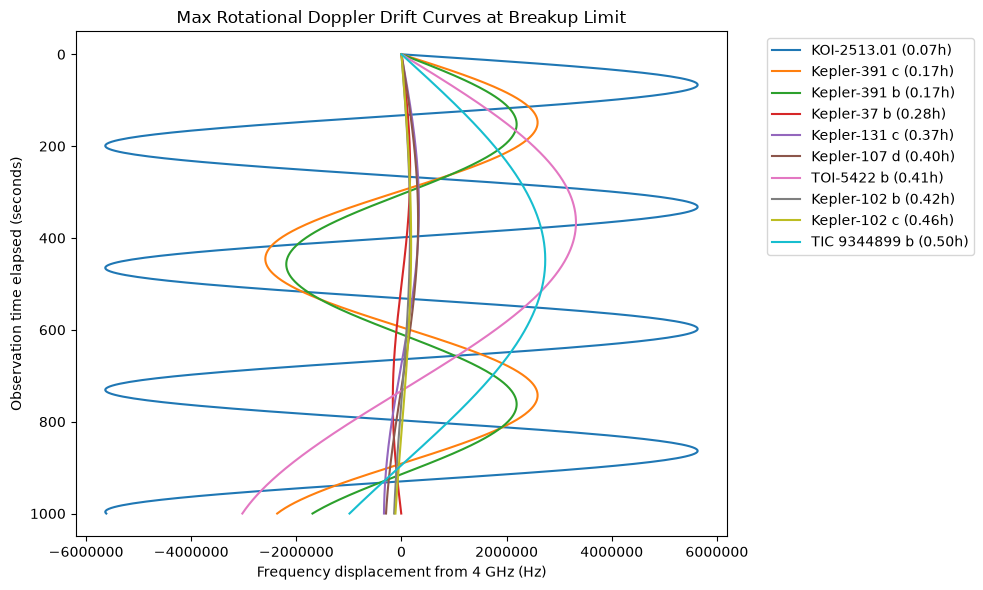

In [3]:
G = 6.67430e-11
R_earth_m = 6.3781e6     # Earth radius in meters
c = 3e8
f0 = 4e9                 # Rest frequency (4 GHz)
T_obs = 1000              # Observation window (seconds)

# 3. Calculate P_breakup and surface rotational speed for each planet
breakup_records = []

for _, row in df_sorted.iterrows():
    name = row['pl_name']
    density = row['pl_dens']
    radius_m = row['pl_rade'] * R_earth_m # Convert Earth radii to meters
    rho = density * 1000.0    # Convert density to kg/m^3
    # Equation (9): P_breakup in seconds
    P_sec = np.sqrt((3 * np.pi) / (G * rho))
    P_hr = P_sec / 3600.0
    
    # Rotational angular velocity (rad/s) and tangential velocity at equator (m/s)
    omega = (2 * np.pi) / P_sec
    v_rot = omega * radius_m
    
    breakup_records.append({
        'pl_name': name,
        'pl_dens': density,
        'P_breakup_hr': P_hr,
        'v_rot': v_rot
    })

df_breakup = pd.DataFrame(breakup_records).sort_values('P_breakup_hr')
print("Top 10 planets with shortest physical breakup periods:")
print(df_breakup.head(10))

plt.figure(figsize=(10, 6))

t = np.linspace(0, T_obs, 500)

for _, row in df_breakup.head(10).iterrows():
    name = row['pl_name']
    v_rot = row['v_rot']
    P_sec = row['P_breakup_hr'] * 3600.0
    
    # Line-of-sight rotational velocity component over time (using max acceleration phase phi_0 = 0)
    v_rad = v_rot * np.sin(2 * np.pi * t / P_sec)
    delta_f = f0 * (v_rad - v_rad[0]) / c    # Frequency displacement relative to t=0
    
    plt.plot(delta_f, t, label=f"{name} ({row['P_breakup_hr']:.2f}h)")

plt.gca().invert_yaxis()
plt.ticklabel_format(style='plain', useOffset=False)
plt.xlabel('Frequency displacement from 4 GHz (Hz)')
plt.ylabel('Observation time elapsed (seconds)')
plt.title('Max Rotational Doppler Drift Curves at Breakup Limit')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

C:\Users\Evane\AppData\Local\Temp\ipykernel_5324\2685562373.py:107: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\Evane\AppData\Local\Temp\ipykernel_5324\2685562373.py:109: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig3.show()


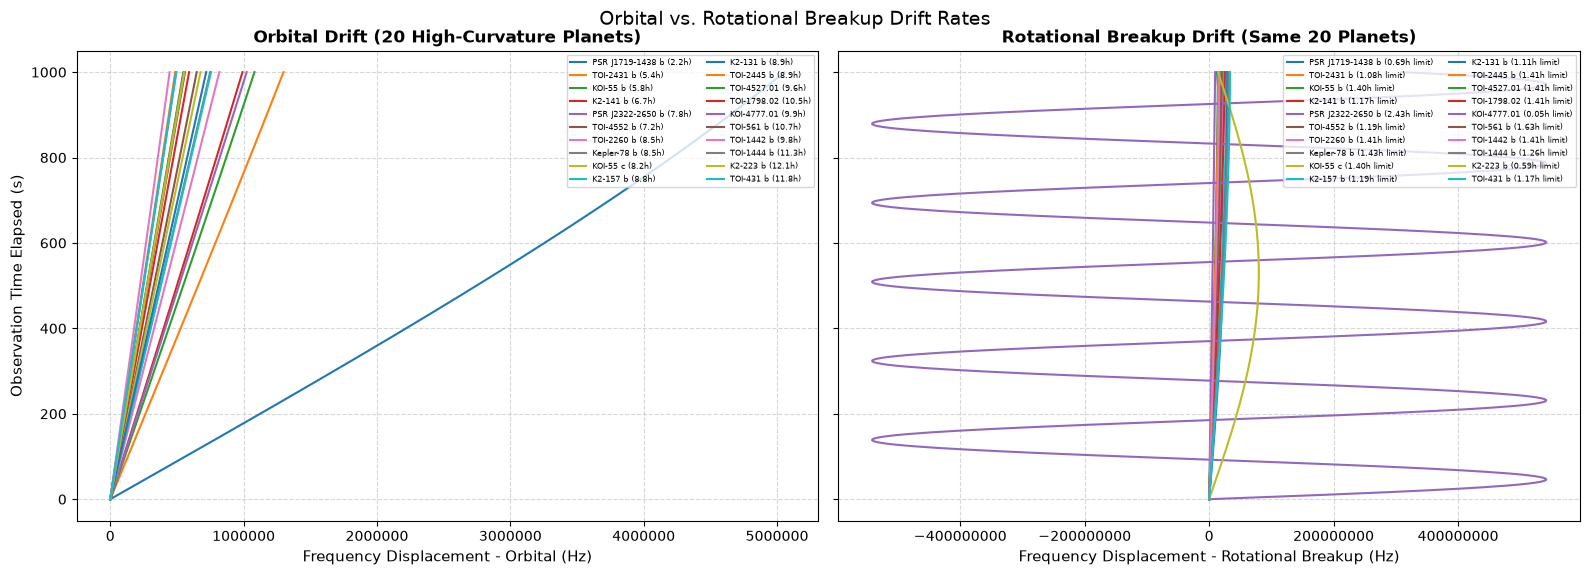

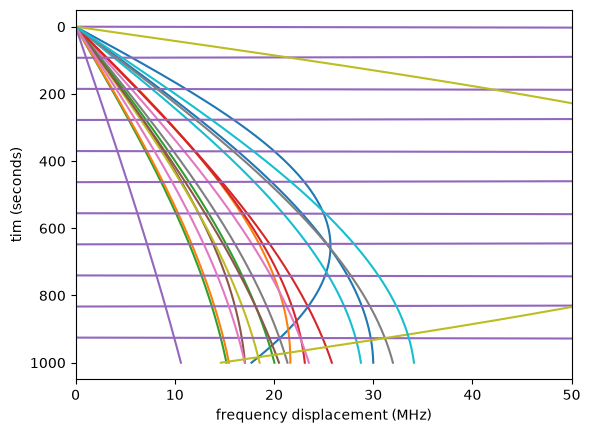

In [8]:
G = 6.67430e-11  # m^3 kg^-1 s^-2
c = 3e8          # Speed of Light (m/s)
f0 = 4.0e9       # Reference frequency (Hz)
t_obs = 1000.0   # Total observation time (s)
t = np.linspace(0, t_obs, 500)

def calculate_breakup_period(row, df_master):
    name = row['pl_name']
    match = df_master[df_master['pl_name'] == name]
    if match.empty:
        return np.nan
    
    rho_g_cm3 = match.iloc[0].get('pl_dens', np.nan)
    r_planet_val = match.iloc[0].get('pl_rade', 1.0)
    
    # If density is missing/NaN, estimate it from mass & radius, or use a default rocky density
    if pd.isna(rho_g_cm3) or rho_g_cm3 <= 0:
        mass_earth = match.iloc[0].get('pl_bmasse', np.nan)  # Correct column: pl_bmasse
        if pd.notna(mass_earth) and pd.notna(r_planet_val) and r_planet_val > 0:
            mass_kg = mass_earth * 5.972e24
            radius_m = r_planet_val * 6.371e6
            volume_m3 = (4.0 / 3.0) * np.pi * (radius_m ** 3)
            rho_kg_m3 = mass_kg / volume_m3
            rho_g_cm3 = rho_kg_m3 / 1000.0
        else:
            rho_g_cm3 = 5.5  # Fallback default density for rocky/dense exoplanets

    if pd.notna(rho_g_cm3) and rho_g_cm3 > 0:
        rho_kg_m3 = rho_g_cm3 * 1000.0
        P_breakup_sec = np.sqrt((3.0 * np.pi) / (G * rho_kg_m3))
        return P_breakup_sec / 3600.0
    return np.nan

def evaluate_curvature(P_hours, a_AU, f0=4e9, T_obs=300):
    P_sec = P_hours * 3600
    a_m = a_AU * 1.496e11
    v_orb = (2 * np.pi * a_m) / P_sec
    t_eval = np.linspace(0, T_obs, 500)
    v_rad = v_orb * np.sin(2 * np.pi * t_eval / P_sec)
    delta_f = f0 * (v_rad - v_rad[0]) / c
    
    p_fit = np.polyfit(t_eval, delta_f, deg=1)
    linear_trend = np.polyval(p_fit, t_eval)
    rmse = np.sqrt(np.mean((delta_f - linear_trend)**2))
    return t_eval, delta_f, rmse
    
table = NasaExoplanetArchive.query_criteria(
    table="ps",
    select="pl_name, pl_orbper, pl_orbsmax, pl_dens, pl_bmasse, pl_rade",
    where="pl_orbper IS NOT NULL AND pl_orbsmax IS NOT NULL AND default_flag=1"
)
df = table.to_pandas()

df['pl_orbper_hr'] = df['pl_orbper'] * 24.0 # Convert orbital period from days to hours

# Calculate RMSE based on orbital period to find the high-curvature planets
df['rmse_hz'] = [
    evaluate_curvature(row['pl_orbper_hr'], row['pl_orbsmax'], f0=f0, T_obs=t_obs)[2]
    for _, row in df.iterrows()
]

# Select the top 20 high-curvature planets
curved_planets = df[df['rmse_hz'] > 5].sort_values('rmse_hz', ascending=False).head(20).copy()

# Compute the specific rotational breakup period for these 20 planets
curved_planets['P_breakup_hr'] = curved_planets.apply(lambda r: calculate_breakup_period(r, df), axis=1)
curved_planets = curved_planets.dropna(subset=['P_breakup_hr'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
fig3, ax3 = plt.subplots(1, 1)

for _, row in curved_planets.iterrows():
    name = row['pl_name']
    t_eval, delta_f_orb, _ = evaluate_curvature(row['pl_orbper_hr'], row['pl_orbsmax'], f0=f0, T_obs=t_obs)
    ax1.plot(delta_f_orb, t_eval, label=f"{name} ({row['pl_orbper_hr']:.1f}h)")
    P_breakup_hr = row['P_breakup_hr']
    
    t_eval, delta_f_rot, _ = evaluate_curvature(P_breakup_hr, row['pl_orbsmax'], f0=f0, T_obs=t_obs)
    ax3.plot((delta_f_orb+delta_f_rot)/1e6, t_eval)
ax3.invert_yaxis()
ax3.set_xlabel("frequency displacement (MHz)")
ax3.set_ylabel("tim (seconds)")
ax1.invert_yaxis()
ax1.ticklabel_format(style='plain', useOffset=False)
ax1.set_xlabel('Frequency Displacement - Orbital (Hz)', fontsize=11)
ax1.set_ylabel('Observation Time Elapsed (s)', fontsize=11)
ax1.set_title(f'Orbital Drift ({len(curved_planets)} High-Curvature Planets)', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right', fontsize='xx-small', ncol=2)
ax1.grid(True, linestyle='--', alpha=0.5)

for _, row in curved_planets.iterrows():
    name = row['pl_name']
    P_breakup_hr = row['P_breakup_hr']
    
    t_eval, delta_f_rot, _ = evaluate_curvature(P_breakup_hr, row['pl_orbsmax'], f0=f0, T_obs=t_obs)
    ax2.plot(delta_f_rot, t_eval, label=f"{name} ({P_breakup_hr:.2f}h limit)")

ax2.invert_yaxis()
ax2.ticklabel_format(style='plain', useOffset=False)
ax2.set_xlabel('Frequency Displacement - Rotational Breakup (Hz)', fontsize=11)
ax2.set_title('Rotational Breakup Drift (Same 20 Planets)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', fontsize='xx-small', ncol=2)
ax2.grid(True, linestyle='--', alpha=0.5)

fig.suptitle(f' Orbital vs. Rotational Breakup Drift Rates ', fontsize=14, y=0.95)
fig.tight_layout()
fig.show()
ax3.set_xlim(0, 50)
fig3.show()

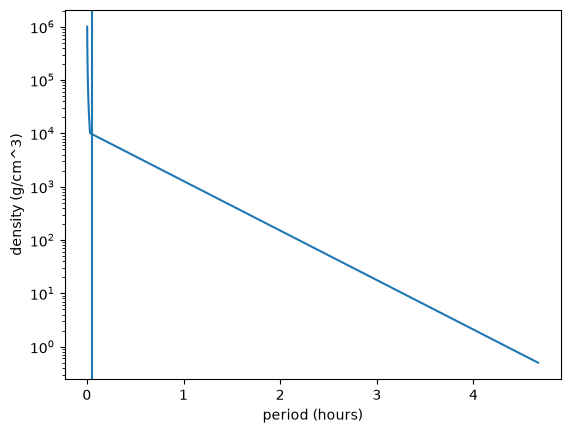

In [14]:
rho_vec = np.linspace(0.5, 1000000, 100)
def p_calc(rho_g_cm3):
    
    rho_kg_m3 = rho_g_cm3 * 1000.0
    P_breakup_sec = np.sqrt((3.0 * np.pi) / (G * rho_kg_m3))
    return P_breakup_sec / 3600.0
p_vec = p_calc(rho_vec)
plt.plot(p_vec, rho_vec)
plt.xlabel("period (hours)")
plt.ylabel("density (g/cm^3)")
plt.axvline(0.055)
plt.yscale("log")
plt.show()